# Driving the Green Transition: EV Adoption vs Renewable Energy Trajectories

# Importing Libraries and Checking Dataset Availability

In [56]:
# Importing the main libraries I'll need for the analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from pathlib import Path
import warnings

# I’ll ignore small warnings to keep the notebook output clean
warnings.filterwarnings("ignore")

# Setting the filenames for the datasets
EV_FILE = "Global EV Data 2024 (1).csv"
OWID_FILE = "owid-energy-data.csv"

# Just checking whether the files are actually present in the working directory
print("EV exists:", Path(EV_FILE).exists())
print("OWID exists:", Path(OWID_FILE).exists())

EV exists: True
OWID exists: True


This step imports all the essential libraries for data handling and visualisation, sets the filenames for the EV and energy datasets, and suppresses minor warnings to keep the output clean. I also include a quick check to confirm that both data files are present in the working directory before moving on to loading them.

# Loading and Inspecting the Raw Datasets

In [57]:
# Loading both datasets into dataframes
df_ev_raw = pd.read_csv(EV_FILE)        # Raw Global EV dataset
df_energy_raw = pd.read_csv(OWID_FILE)  # Raw OWID energy dataset

# Printing the shape of each dataset to get a quick idea of their size
print(df_ev_raw.shape)      # (rows, columns) for EV data
print(df_energy_raw.shape)  # (rows, columns) for energy data

# Previewing the first few rows of the EV dataset
df_ev_raw.head()

(12654, 8)
(23195, 130)


,region,category,parameter,mode,powertrain,year,unit,value
0,Australia,Historical,EV stock share,Cars,EV,2011,percent,0.00039
1,Australia,Historical,EV sales share,Cars,EV,2011,percent,0.00650
2,Australia,Historical,EV sales,Cars,BEV,2011,Vehicles,49.00000
3,Australia,Historical,EV stock,Cars,BEV,2011,Vehicles,49.00000
4,Australia,Historical,EV stock,Cars,BEV,2012,Vehicles,220.00000


In this step, I load both the Global EV dataset and the OWID energy dataset into pandas DataFrames. After loading, I quickly check their dimensions to understand how many rows and columns each dataset contains.Finally, I preview the first few rows of the EV dataset to get an initial sense of the structure and features available.

# Exploratory Data Analysis (EDA)

# Data Cleaning: Preparing the EV Stock Share Dataset

In [58]:
# Filtering the EV dataset to keep only the relevant records
df_ev = df_ev_raw[
    (df_ev_raw["parameter"] == "EV stock share") &
    (df_ev_raw["mode"] == "Cars") &
    (df_ev_raw["powertrain"] == "EV") &
    (df_ev_raw["unit"] == "percent") &
    (df_ev_raw["region"] != "World")
].copy()

# Renaming columns to more convenient names for analysis
df_ev = df_ev.rename(columns={"region": "country", "value": "ev_stock_share"})

# Converting year and EV share to numeric just to make sure
df_ev["year"] = pd.to_numeric(df_ev["year"], errors="coerce")
df_ev["ev_stock_share"] = pd.to_numeric(df_ev["ev_stock_share"], errors="coerce")

# Previewing the cleaned EV dataset
df_ev.head()

,country,category,parameter,mode,powertrain,year,unit,ev_stock_share
0,Australia,Historical,EV stock share,Cars,EV,2011,percent,0.00039
7,Australia,Historical,EV stock share,Cars,EV,2012,percent,0.00240
12,Australia,Historical,EV stock share,Cars,EV,2013,percent,0.00460
19,Australia,Historical,EV stock share,Cars,EV,2014,percent,0.01400
24,Australia,Historical,EV stock share,Cars,EV,2015,percent,0.02700


In this step, I filter the raw EV dataset to keep only the records that relate specifically to EV stock share for electric cars, expressed in percentage terms. I also exclude the global “World” values so the analysis focuses only on individual countries. After that, I rename a few columns to more intuitive names and convert key fields (year and EV share) to numeric formats to ensure they are ready for analysis. Finally, I preview the cleaned dataset to confirm everything looks correct.

# Fixing the Scale of EV Stock Share Values

In [59]:
# Checking the median EV stock share to understand the scale of the values
median_val = df_ev["ev_stock_share"].median()

# If the median is less than 1, the values are likely in fraction form (e.g., 0.12 instead of 12%)
# In that case, convert the values to proper percentages by multiplying by 100
if median_val < 1:
    df_ev["ev_stock_share"] *= 100
    print("EV stock share scaled from fraction → percent")

# Preview the updated EV dataset
df_ev.head()

EV stock share scaled from fraction → percent


,country,category,parameter,mode,powertrain,year,unit,ev_stock_share
0,Australia,Historical,EV stock share,Cars,EV,2011,percent,0.039
7,Australia,Historical,EV stock share,Cars,EV,2012,percent,0.240
12,Australia,Historical,EV stock share,Cars,EV,2013,percent,0.460
19,Australia,Historical,EV stock share,Cars,EV,2014,percent,1.400
24,Australia,Historical,EV stock share,Cars,EV,2015,percent,2.700


This step checks whether the EV stock share values are stored as fractions instead of percentages. If the median value is below 1, it indicates fractional data (e.g., 0.25 instead of 25%), so the values are scaled up by multiplying by 100. This ensures the dataset is consistently expressed in percentage terms before analysis.

# Selecting and Cleaning Key Columns from the Energy Dataset

In [60]:
# Selecting only the columns needed for the analysis
energy_cols = ["country", "year", "renewables_share_energy", 
               "renewables_consumption", "gdp", "population"]

# Keeping only columns that actually exist in the OWID dataset
energy_cols = [c for c in energy_cols if c in df_energy_raw.columns]

# Creating a clean subset of the raw energy dataset
df_energy = df_energy_raw[energy_cols].copy()

# Making sure 'year' is numeric for consistency
df_energy["year"] = pd.to_numeric(df_energy["year"], errors="coerce")

# Previewing the cleaned energy dataset
df_energy.head()

,country,year,renewables_share_energy,renewables_consumption,gdp,population
0,ASEAN (Ember),2000,NaN,NaN,NaN,NaN
1,ASEAN (Ember),2001,NaN,NaN,NaN,NaN
2,ASEAN (Ember),2002,NaN,NaN,NaN,NaN
3,ASEAN (Ember),2003,NaN,NaN,NaN,NaN
4,ASEAN (Ember),2004,NaN,NaN,NaN,NaN


In this step, I extract the specific energy-related variables needed for the analysis, such as renewable energy share, consumption, GDP, and population. I also ensure that the year column is converted to a numeric type so it can be merged and analysed consistently with the EV dataset. Finally, I preview the cleaned subset of the energy data.

# Country Name Alignment & Cleaning

In [61]:
# Creating a mapping to standardize country names across both datasets
country_map = {
    "Czech Republic": "Czechia",
    "Turkiye": "Turkey",
    "Korea": "South Korea",
    "USA": "United States"
}

# Applying the country name corrections to both datasets
df_ev["country"] = df_ev["country"].replace(country_map)
df_energy["country"] = df_energy["country"].replace(country_map)

# Removing aggregated or non-country entries that shouldn't be included
bad = ["EU27", "World", "Rest of the world"]
df_ev = df_ev[~df_ev["country"].isin(bad)]
df_energy = df_energy[~df_energy["country"].isin(bad)]

# Previewing the cleaned EV dataset again
df_ev.head()

,country,category,parameter,mode,powertrain,year,unit,ev_stock_share
0,Australia,Historical,EV stock share,Cars,EV,2011,percent,0.039
7,Australia,Historical,EV stock share,Cars,EV,2012,percent,0.240
12,Australia,Historical,EV stock share,Cars,EV,2013,percent,0.460
19,Australia,Historical,EV stock share,Cars,EV,2014,percent,1.400
24,Australia,Historical,EV stock share,Cars,EV,2015,percent,2.700


In this step, I standardize country names in both datasets so they match when merging later. I also remove aggregate regions like “EU27” and “World,” since the analysis focuses only on individual countries. This ensures that both datasets are aligned and ready for accurate country-level comparisons.

# Merging the EV and Energy Datasets

In [62]:
# Merging the cleaned EV dataset with the filtered energy dataset
# The merge is done on both 'country' and 'year' to align matching records
df = pd.merge(
    df_ev,
    df_energy,
    on=["country", "year"],
    how="inner"   # Only keep rows where both datasets have matching entries
)

# Dropping rows where either EV stock share or renewables share is missing
df = df.dropna(subset=["ev_stock_share", "renewables_share_energy"])

# Keeping only the analysis period of interest (2010–2023)
df = df[(df["year"] >= 2010) & (df["year"] <= 2023)]

# Sorting for cleaner inspection and resetting index
df = df.sort_values(["country", "year"]).reset_index(drop=True)

# Displaying the first rows and the final dataset dimensions
df.head(), df.shape

(     country    category       parameter  mode powertrain  year     unit  \
 0  Australia  Historical  EV stock share  Cars         EV  2011  percent   
 1  Australia  Historical  EV stock share  Cars         EV  2012  percent   
 2  Australia  Historical  EV stock share  Cars         EV  2013  percent   
 3  Australia  Historical  EV stock share  Cars         EV  2014  percent   
 4  Australia  Historical  EV stock share  Cars         EV  2015  percent   
 
    ev_stock_share  renewables_share_energy  renewables_consumption  \
 0           0.039                    5.392                  83.776   
 1           0.240                    5.400                  82.696   
 2           0.460                    6.173                  95.674   
 3           1.400                    5.663                  88.418   
 4           2.700                    5.955                  95.058   
 
             gdp  population  
 0  1.024000e+12  22479723.0  
 1  1.062663e+12  22852597.0  
 2  1.086068e+1

This step merges the processed EV and energy datasets using country and year as the key fields. After merging, rows with missing EV stock share or renewable energy share values are removed, and the data is restricted to the period from 2010 to 2023 for consistency. Finally, the dataset is sorted and cleaned for analysis, and the merged output is displayed.

# Distribution of EV Stock Share and Renewable Energy Share

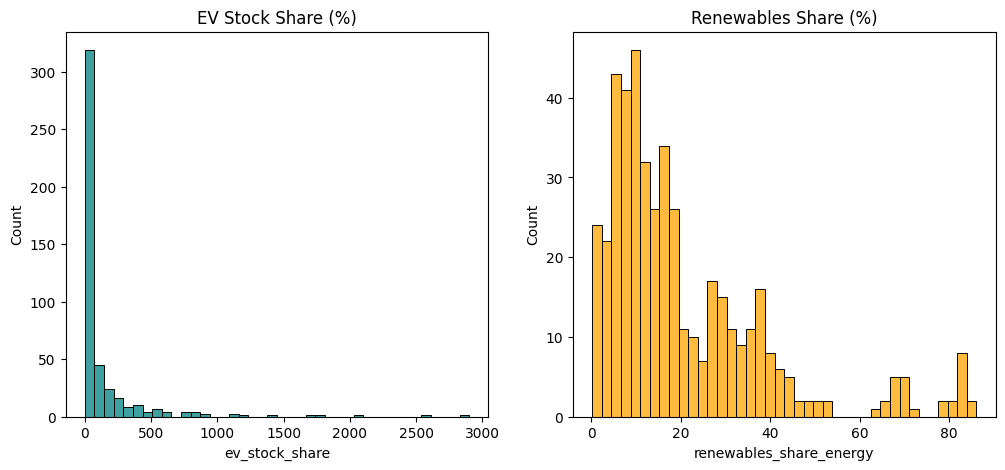

In [63]:
# Creating two side-by-side histograms to understand the distribution
# of EV stock share and renewable energy share

plt.figure(figsize=(12,5))   # Setting the overall figure size

# Histogram for EV stock share
plt.subplot(1,2,1)           # First subplot (left side)
sns.histplot(df["ev_stock_share"], bins=40, color="teal")
plt.title("EV Stock Share (%)")

# Histogram for renewables share
plt.subplot(1,2,2)           # Second subplot (right side)
sns.histplot(df["renewables_share_energy"], bins=40, color="orange")
plt.title("Renewables Share (%)")

plt.show()                   # Display both plots

This step visualises the distribution of two key variables in the combined dataset: EV stock share and renewable energy share. Plotting both histograms helps identify skewness, outliers, and general spread, giving an initial understanding of how each variable behaves before deeper analysis.

# Checking Missing Values in the Merged Dataset

In [64]:
# Checking how many missing values are present in each column
missing_counts = df.isna().sum()

print("Missing Value Counts Per Column (Before Interpolation):")
print(missing_counts)

Missing Value Counts Per Column (Before Interpolation):
country                     0
category                    0
parameter                   0
mode                        0
powertrain                  0
year                        0
unit                        0
ev_stock_share              0
renewables_share_energy     0
renewables_consumption      0
gdp                        59
population                  0
dtype: int64


This step checks the number of missing values in each column of the merged dataset. Identifying missing data early helps determine whether interpolation, removal, or other cleaning steps are needed before analysis.

# Yearly Correlation Between EV Adoption and Renewable Energy Share

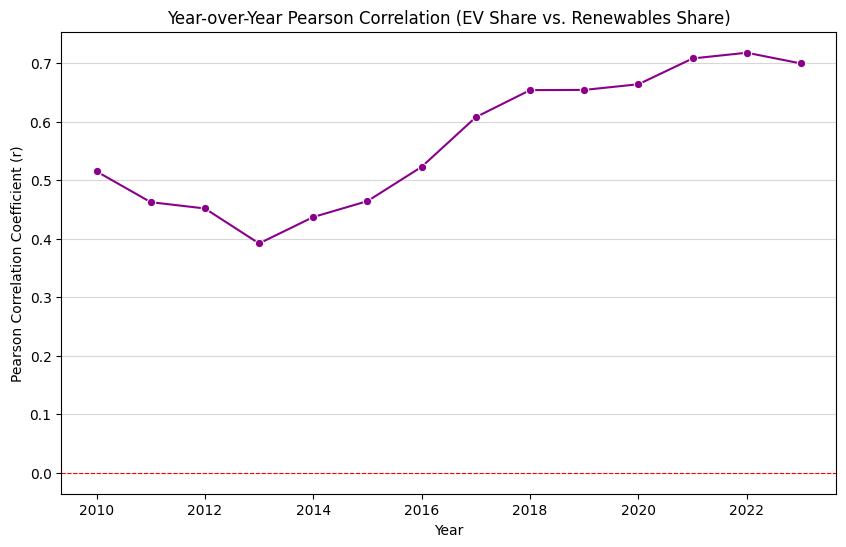

    year  correlation_r
0   2010       0.515140
1   2011       0.462509
2   2012       0.451733
3   2013       0.391929
4   2014       0.437084
5   2015       0.464314
6   2016       0.522918
7   2017       0.607843
8   2018       0.654045
9   2019       0.654388
10  2020       0.664091
11  2021       0.708184
12  2022       0.717976
13  2023       0.699586


In [65]:
# Calculating the year-wise Pearson correlation between EV stock share and renewable energy share.
# For each year, we group the data and compute the correlation between the two variables.
df_interp = df.interpolate()
corr_over_time = df_interp.groupby('year').apply(
    lambda x: x['ev_stock_share'].corr(x['renewables_share_energy'])
).reset_index(name='correlation_r')

# Plotting how the correlation changes over time
plt.figure(figsize=(10, 6))
sns.lineplot(data=corr_over_time, x='year', y='correlation_r', marker='o', color='darkmagenta')

# Adding a horizontal reference line at correlation = 0
plt.axhline(0, color='red', linestyle='--', linewidth=0.8)

plt.title("Year-over-Year Pearson Correlation (EV Share vs. Renewables Share)")
plt.ylabel("Pearson Correlation Coefficient (r)")
plt.xlabel("Year")
plt.grid(True, axis='y', alpha=0.5)

# Saving the figure for report use
plt.savefig("eda_correlation_over_time.png")

plt.show()

# Displaying the resulting correlation values
print(corr_over_time)

This step calculates how the relationship between EV stock share and renewable energy share changes over time. For each year, I compute the Pearson correlation between the two variables across all countries. The resulting trend line helps reveal whether the link between EV adoption and renewable energy strengthening, weakening, or remaining stable over the years. I also add a horizontal reference line at zero to indicate the point where the relationship shifts from positive to negative.

Overall Pearson Correlation Between EV Share and Renewable Energy Share

In [66]:
from scipy.stats import pearsonr

# Selecting only the two variables needed for correlation and dropping any remaining missing values
corr_df = df_interp[["ev_stock_share", "renewables_share_energy"]].dropna()

# Calculating the overall Pearson correlation coefficient and p-value
# r  = strength + direction of the relationship
# p  = statistical significance of the correlation
r, p = pearsonr(corr_df.iloc[:, 0], corr_df.iloc[:, 1])

# Displaying the results
print("Overall Pearson correlation:", r)
print("p-value:", p)

Overall Pearson correlation: 0.44312599276246967
p-value: 2.353546815668609e-23


In this step, I calculate the overall Pearson correlation between EV stock share and renewable energy share using the cleaned, interpolated dataset. This gives a single numerical value (r) representing the strength and direction of the relationship, along with the p-value indicating whether the correlation is statistically significant.

# Interpolating Missing Values for Key Variables

In [67]:
# Function to interpolate small gaps in time-series data for each country
def interp_short(g, cols, max_gap=2):
    # Sort by year and use year as the index for proper interpolation
    g = g.sort_values("year").set_index("year")
    
    # For each selected column, fill short missing gaps using linear interpolation
    # max_gap=2 means it will only interpolate stretches of missing values up to 2 years long
    for c in cols:
        g[c] = g[c].interpolate(method="linear", limit=max_gap, limit_direction="both")
    
    # Return the cleaned DataFrame with the year column restored
    return g.reset_index()

# Apply the interpolation function to each country separately
df_interp = df.groupby("country").apply(lambda g: 
    interp_short(g, ["ev_stock_share", "renewables_share_energy"], max_gap=2)
).reset_index(drop=True)

# Preview the interpolated dataset
df_interp.head()

,year,country,category,parameter,mode,powertrain,unit,ev_stock_share,renewables_share_energy,renewables_consumption,gdp,population
0,2011,Australia,Historical,EV stock share,Cars,EV,percent,0.039,5.392,83.776,1.024000e+12,22479723.0
1,2012,Australia,Historical,EV stock share,Cars,EV,percent,0.240,5.400,82.696,1.062663e+12,22852597.0
2,2013,Australia,Historical,EV stock share,Cars,EV,percent,0.460,6.173,95.674,1.086068e+12,23236224.0
3,2014,Australia,Historical,EV stock share,Cars,EV,percent,1.400,5.663,88.418,1.113888e+12,23595552.0
4,2015,Australia,Historical,EV stock share,Cars,EV,percent,2.700,5.955,95.058,1.139303e+12,23947955.0


This function performs short-gap interpolation for each country, filling small missing stretches in EV stock share and renewable energy share values. It ensures the time series remains smooth without introducing large artificial jumps. After applying it to every country, the interpolated dataset is returned for further analysis.

# Identifying Top Countries by EV Stock Share Growth

In [68]:
# Making a copy of the interpolated dataset so we can generate summary statistics
df_final = df_interp.copy()

# For each country, calculate:
# - ev_start: the first available EV stock share value
# - ev_end: the most recent EV stock share value
summary = df_final.groupby("country").agg(
    ev_start=("ev_stock_share", lambda s: s.iloc[0]),
    ev_end=("ev_stock_share", lambda s: s.iloc[-1])
)

# Compute the overall change in EV stock share from start → end
summary["change"] = summary["ev_end"] - summary["ev_start"]

# Identify the top 6 countries with the highest EV stock share growth
top6 = summary.sort_values("change", ascending=False).head(6).index.tolist()
print("Top 6 countries:", top6)

Top 6 countries: ['Norway', 'Iceland', 'Sweden', 'Denmark', 'Netherlands', 'Belgium']


In this step, I calculate how EV stock share has changed over time for each country. I do this by grouping the interpolated dataset, extracting each country's first and last recorded EV share, and then computing the difference between them. This allows me to identify which countries experienced the largest growth in EV adoption. Finally, I sort the results and display the top six countries with the highest overall increase.

# Assigning Colors for Top Countries in Visualisations

In [69]:
# Defining custom colors for specific countries that appear in the Top 6 list.
# These color hex codes are manually assigned for visual consistency in plots.
colors = {
    "Norway": "#1b9e77",
    "Iceland": "#d95f02",
    "Sweden": "#7570b3",
    "Denmark": "#e7298a",
    "Netherlands": "#66a61e",
    "Belgium": "#e6ab02"
}

# If any of the top 6 countries aren’t already in the dictionary above,
# assign them a color from Plotly’s built-in "Safe" qualitative palette.
safe = px.colors.qualitative.Safe
i = 0
for c in top6:
    if c not in colors:
        colors[c] = safe[i % len(safe)]
        i += 1

# Display the final color dictionary
colors

{'Norway': '#1b9e77',
 'Iceland': '#d95f02',
 'Sweden': '#7570b3',
 'Denmark': '#e7298a',
 'Netherlands': '#66a61e',
 'Belgium': '#e6ab02'}

To prepare for consistent visualisation later, I create a custom color dictionary for the top six countries with the highest EV stock share growth. Some countries already have manually chosen colors, and for any remaining ones, I automatically assign colors from Plotly’s “Safe” palette. This ensures that all countries will appear clearly and distinctly in the final charts.

# Animated Relationship Between EV Adoption and Renewable Energy Share (2010–2023)

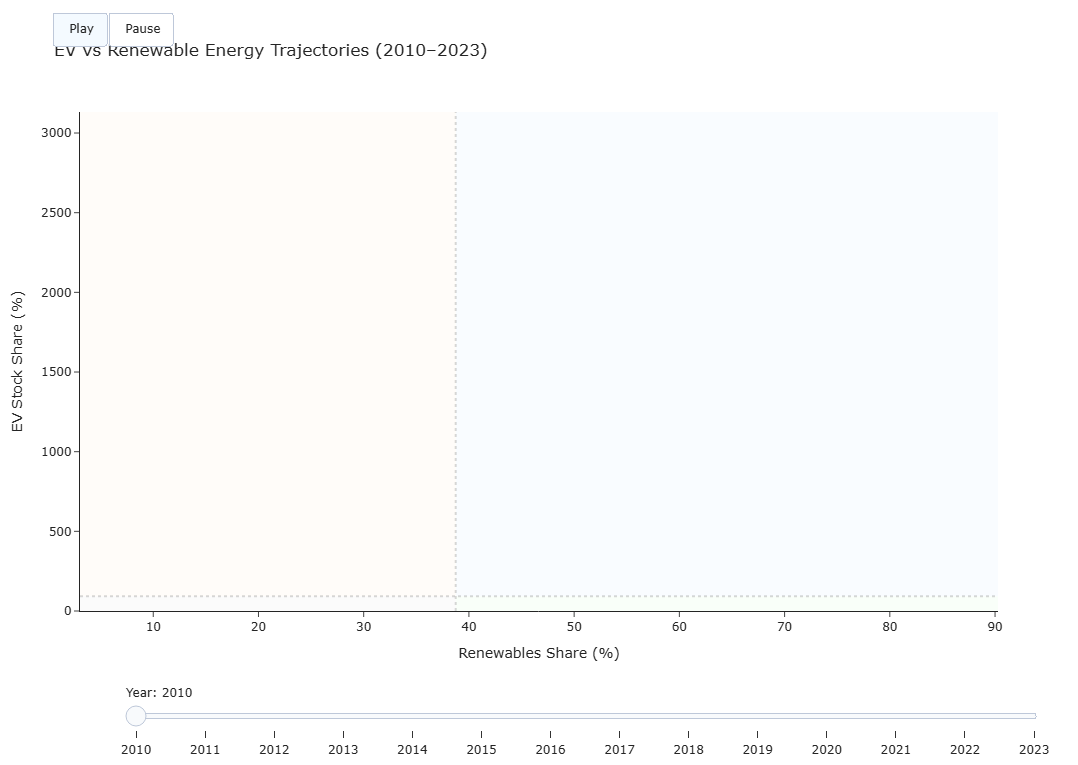

In [73]:
import plotly.graph_objects as go

# Filter data to only the selected top-performing countries
df_anim = df_final[df_final["country"].isin(top6)].copy()

# Extract all years for building animation frames
years = sorted(df_anim["year"].unique())

# Determine axis limits from the dataset
xmin = df_anim["renewables_share_energy"].min()
xmax = df_anim["renewables_share_energy"].max()
ymin = df_anim["ev_stock_share"].min()
ymax = df_anim["ev_stock_share"].max()

# Add small padding to top and right edges so curves do not touch the border
x_pad = (xmax - xmin) * 0.05
y_pad = (ymax - ymin) * 0.08

# Median thresholds used to divide plot into four quadrants
x_med = df_anim["renewables_share_energy"].median()
y_med = df_anim["ev_stock_share"].median()

# Create base figure and define axes
fig = go.Figure()
fig.update_layout(
    title="EV vs Renewable Energy Trajectories (2010–2023)",
    xaxis=dict(title="Renewables Share (%)", range=[xmin, xmax + x_pad]),
    yaxis=dict(title="EV Stock Share (%)", range=[ymin, ymax + y_pad]),
    width=1200,
    height=750,
    template="simple_white",
    legend=dict(x=1.05, y=1)
)

# Helper function to add shaded quadrant rectangles
def add_rect(x0, x1, y0, y1, color):
    fig.add_shape(
        type="rect",
        x0=x0, x1=x1,
        y0=y0, y1=y1,
        xref="x", yref="y",
        fillcolor=color,
        opacity=0.25,
        line=dict(width=0),
        layer="below"
    )

# Apply quadrant shading
add_rect(xmin, x_med, ymin, y_med, "rgba(220,220,220,0.4)")          # Low EV, Low Renewables
add_rect(x_med, xmax + x_pad, ymin, y_med, "rgba(200,255,200,0.4)")  # High Renewables
add_rect(xmin, x_med, y_med, ymax + y_pad, "rgba(255,230,200,0.4)")  # High EV
add_rect(x_med, xmax + x_pad, y_med, ymax + y_pad, "rgba(200,230,255,0.4)")  # Synergy zone

# Add median lines for quadrant boundaries
fig.add_shape(
    type="line",
    x0=x_med, x1=x_med,
    y0=ymin, y1=ymax + y_pad,
    line=dict(color="gray", width=2, dash="dot"),
    layer="above"
)

fig.add_shape(
    type="line",
    x0=xmin, x1=xmax + x_pad,
    y0=y_med, y1=y_med,
    line=dict(color="gray", width=2, dash="dot"),
    layer="above"
)

# Add empty traces for each country (filled during animation)
for country in top6:
    fig.add_trace(go.Scatter(
        x=[], y=[],
        mode="lines+markers",
        name=country,
        line=dict(color=colors[country], width=3),
        marker=dict(size=8, color=colors[country], line=dict(width=0.5, color="black"))
    ))

# Build animation frames showing progressive year-by-year trajectories
frames = []
for year in years:
    frame_data = []

    for country in top6:
        d_country = df_anim[df_anim["country"] == country]
        d_years = d_country[d_country["year"] <= year]

        frame_data.append(go.Scatter(
            x=d_years["renewables_share_energy"],
            y=d_years["ev_stock_share"],
            mode="lines+markers",
            line=dict(color=colors[country], width=3),
            marker=dict(size=8, color=colors[country], line=dict(width=0.5, color="black"))
        ))

    frames.append(go.Frame(data=frame_data, name=str(year)))

fig.frames = frames

# Build slider to manually scrub through years
sliders = [{
    "steps": [
        {
            "args": [[str(year)], {"frame": {"duration": 400, "redraw": True},
                                   "mode": "immediate"}],
            "label": str(year),
            "method": "animate"
        }
        for year in years
    ],
    "transition": {"duration": 300},
    "x": 0.05,
    "y": -0.1,
    "currentvalue": {"prefix":"Year: "}
}]

# Add Play and Pause buttons
fig.update_layout(
    updatemenus=[{
        "type": "buttons",
        "direction": "right",
        "x": 0.1,
        "y": 1.2,
        "buttons": [
            {
                "label": " Play",
                "method": "animate",
                "args": [None, {
                    "frame": {"duration": 450, "redraw": True},
                    "fromcurrent": True
                }]
            },
            {
                "label": " Pause",
                "method": "animate",
                "args": [[None], {
                    "frame": {"duration": 0},
                    "mode": "immediate"
                }]
            }
        ]
    }],
    sliders=sliders
)

# Show the animated visualisation
fig.show()


This cell creates an animated Plotly visualisation that shows how the top-performing countries have progressed over time in both EV adoption and renewable energy share. I start by setting up the axes, background quadrant shading, and reference median lines. Then I build a separate animation frame for each year so the movement is smooth and easy to follow. The play/pause controls and year slider let viewers explore how each country shifts toward stronger EV–renewable synergy across the timeline.

This visualisation explored how electric vehicle (EV) adoption relates to growth in renewable energy across countries from 2010 to 2023. An animated connected‑scatter plot showed how each country moved through a space defined by EV stock share and renewable energy share, revealing balanced paths where both rose together and cases where EV numbers grew faster than clean power or vice versa. Overall, the results highlight that EVs deliver the strongest climate benefits when countries expand renewable energy at the same time.